In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class EchoMemoryAttention(nn.Module):
    def __init__(self, d_model, d_e, d_v, k_top=4, dynamic_entropy=True):
        """
        Args:
            d_model (int): Hidden dimension 'd' of the transformer.
            d_e (int): Projection dimension for query and keys.
            d_v (int): Projection dimension for value vectors.
            k_top (int): Default or maximum base k to use when dynamic is disabled.
            dynamic_entropy (bool): Whether to dynamically adjust k based on attention score entropy.
        """
        super().__init__()
        self.d_model = d_model
        self.d_e = d_e
        self.d_v = d_v
        self.k_top = k_top
        self.dynamic_entropy = dynamic_entropy

        # Step A: Projection Weights
        self.W_q = nn.Linear(d_model, d_e, bias=False)
        self.W_k = nn.Linear(d_model, d_e, bias=False)
        self.W_v = nn.Linear(d_model, d_v, bias=False)

        # Step D: Gate and Output Projections
        self.W_g = nn.Linear(d_model + d_v, 1) # scalar gate per position
        self.W_out = nn.Linear(d_v, d_model, bias=False)

    def forward(self, h_L, M):
        """
        Args:
            h_L (Tensor): Late state at current position t, Shape: [B, 1, d_model]
            M (Tensor): Past memory bank, Shape: [B, t_past, d_model]
        Returns:
            h_hat (Tensor): Refined hidden state, Shape: [B, 1, d_model]
        """
        B, _, _ = h_L.shape
        t_past = M.shape[1]

        if t_past == 0:
            return h_L

        # --- Step A: Project Query, Keys, and Echo Values ---
        q_t = self.W_q(h_L)       # [B, 1, d_e]
        k_j = self.W_k(M)         # [B, t_past, d_e]
        v_j = self.W_v(M)         # [B, t_past, d_v]

        # --- Step B: Score Relations ---
        scores = torch.bmm(q_t, k_j.transpose(1, 2)) / (self.d_e ** 0.5) # [B, 1, t_past]

        # Compute dynamic top-k using Shannon Entropy if enabled
        if self.dynamic_entropy:
            # Get a probability distribution over the scores for entropy estimation
            probs = F.softmax(scores, dim=-1) # [B, 1, t_past]
            # Calculate Shannon Entropy
            entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1) # [B, 1]
            # Normalize entropy between 0 and 1
            max_entropy = math.log(t_past) if t_past > 1 else 1.0
            norm_entropy = entropy / max_entropy

            # Map entropy to a dynamic k value: higher uncertainty -> larger neighborhood retrieval
            # We scale from minimum 1 to maximum specified by self.k_top
            dynamic_k = 1 + torch.round(norm_entropy * (self.k_top - 1)).long()
            # Clamp and average across batch for unified batch operation, or process batch-maximum
            effective_k = int(torch.clamp(dynamic_k.max(), 1, t_past).item())
        else:
            effective_k = min(self.k_top, t_past)

        # Select the dynamic top-k indices over the last dimension
        topk_scores, topk_indices = torch.topk(scores, k=effective_k, dim=-1)

        # Normalize weights strictly over those k indices
        alpha = F.softmax(topk_scores, dim=-1) # [B, 1, effective_k]

        # --- Step C: Assemble the Echo Vector ---
        gather_indices = topk_indices.unsqueeze(-1).expand(-1, -1, -1, self.d_v)
        v_expanded = v_j.unsqueeze(1).expand(-1, 1, -1, -1)

        v_selected = torch.gather(v_expanded, dim=2, index=gather_indices)
        e_t = torch.sum(alpha.unsqueeze(-1) * v_selected, dim=2) # [B, 1, d_v]

        # --- Step D: Compute Gate & Inject ---
        gate_input = torch.cat([h_L, e_t], dim=-1)
        g_t = torch.sigmoid(self.W_g(gate_input))

        h_hat = h_L + g_t * self.W_out(e_t)
        return h_hat

# --- Quick Verification Run with import math added inside ---
import math
B, d_model, d_e, d_v = 2, 64, 16, 32
t_past = 10

echo_layer = EchoMemoryAttention(d_model, d_e, d_v, k_top=4, dynamic_entropy=True)
M = torch.randn(B, t_past, d_model)
h_L = torch.randn(B, 1, d_model)
out = echo_layer(h_L, M)
print("Dynamic Dynamic-Entropy Output shape:", out.shape)

Dynamic Dynamic-Entropy Output shape: torch.Size([2, 1, 64])


### Comparison of Standard Multi-Head Attention vs. EchoMemoryAttention

Let's implement a standard PyTorch Multi-Head Attention layer to compare its behavior, output distribution, and structure directly with the custom `EchoMemoryAttention` block.

In [ ]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Instantiate both blocks
# Standard MHA block (using PyTorch's native layer for comparison)
# Note: MHA requires query, key, and value. For cross-attention with past memory,
# query is h_L, and key/value are M.
standard_mha = nn.MultiheadAttention(embed_dim=d_model, num_heads=2, batch_first=True)

# Reset random seed for reproducibility
torch.manual_seed(42)

# Prepare inputs
M_test = torch.randn(B, t_past, d_model)
h_L_test = torch.randn(B, 1, d_model)

# 1. Run standard Multi-Head Attention
# In native PyTorch MHA, we also include a residual connection to mimic the structural output comparison
mha_out, mha_weights = standard_mha(query=h_L_test, key=M_test, value=M_test)
final_mha_out = h_L_test + mha_out

# 2. Run EchoMemoryAttention
echo_out = echo_layer(h_L_test, M_test)

# Compare output shapes
print("Standard MHA Output Shape:", final_mha_out.shape)
print("EchoMemoryAttention Output Shape:", echo_out.shape)

# Display raw outputs for inspection
print("\n--- Standard MHA Output (Batch 0, Sequence 0) ---")
print(final_mha_out[0, 0, :10].detach().numpy(), "...")

print("\n--- EchoMemoryAttention Output (Batch 0, Sequence 0) ---")
print(echo_out[0, 0, :10].detach().numpy(), "...")

Standard MHA Output Shape: torch.Size([2, 1, 64])
EchoMemoryAttention Output Shape: torch.Size([2, 1, 64])

--- Standard MHA Output (Batch 0, Sequence 0) ---
[-0.3140193  -0.08566487  1.2515545   0.30021444  0.5927874  -1.4198197
  1.047672    0.01859082 -0.29956648 -0.9296706 ] ...

--- EchoMemoryAttention Output (Batch 0, Sequence 0) ---
[-0.41465408 -0.45786256  0.9178441   0.07872897  0.47103283 -1.0308272
  1.1473708   0.44071668 -0.4498282  -0.97994065] ...


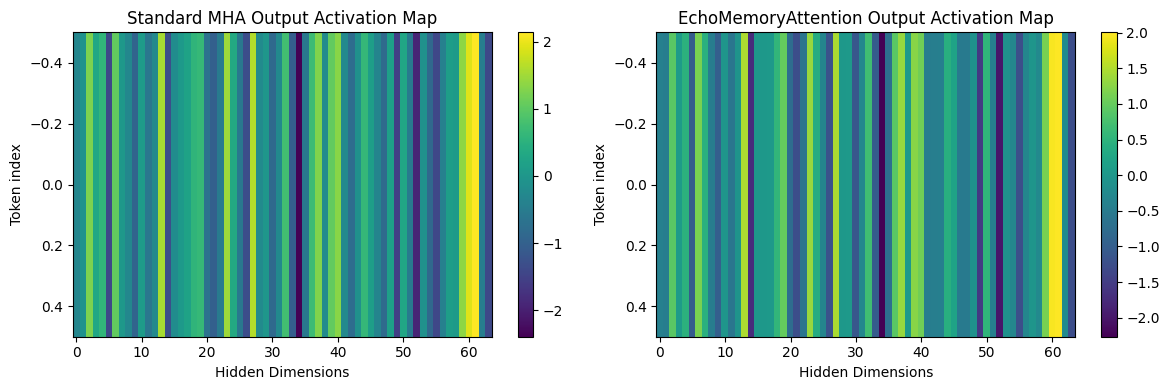

In [ ]:
# Visualize the outputs to analyze the differences visually
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im1 = axes[0].imshow(final_mha_out[0].detach().numpy(), cmap='viridis', aspect='auto')
axes[0].set_title("Standard MHA Output Activation Map")
axes[0].set_xlabel("Hidden Dimensions")
axes[0].set_ylabel("Token index")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(echo_out[0].detach().numpy(), cmap='viridis', aspect='auto')
axes[1].set_title("EchoMemoryAttention Output Activation Map")
axes[1].set_xlabel("Hidden Dimensions")
axes[1].set_ylabel("Token index")
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

### Scaling Up: Deeper Transformer Architectures

Let's design a deeper sequence processor with multiple layers ($N=3$) to observe how the custom top-$k$ gating mechanism impacts feature propagation across a stack of layers compared to standard Multi-Head Attention blocks.

In [ ]:
class DeepStandardTransformer(nn.Module):
    def __init__(self, d_model, n_layers=3, n_heads=2):
        super().__init__()
        self.layers = nn.ModuleList([
            nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True)
            for _ in range(n_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layers)])

    def forward(self, h, M):
        # Propagate through layers sequentially
        for attn, norm in zip(self.layers, self.norms):
            # Multi-head attention layer + residual connection + layer normalization
            attn_out, _ = attn(query=h, key=M, value=M)
            h = norm(h + attn_out)
        return h

class DeepEchoTransformer(nn.Module):
    def __init__(self, d_model, d_e, d_v, n_layers=3, k_top=4):
        super().__init__()
        self.layers = nn.ModuleList([
            EchoMemoryAttention(d_model, d_e, d_v, k_top=k_top)
            for _ in range(n_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layers)])

    def forward(self, h, M):
        # Propagate through custom layers sequentially
        for echo_layer, norm in zip(self.layers, self.norms):
            h = norm(echo_layer(h, M))
        return h

# Instantiate both deeper models
torch.manual_seed(42)
n_layers = 3

deep_standard = DeepStandardTransformer(d_model=d_model, n_layers=n_layers)
deep_echo = DeepEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4)

# Prepare input tensors simulating sequence representation propagation
H_init = torch.randn(B, 1, d_model)
Memory = torch.randn(B, t_past, d_model)

standard_deep_out = deep_standard(H_init, Memory)
echo_deep_out = deep_echo(H_init, Memory)

print("Deep Standard Transformer Output Shape:", standard_deep_out.shape)
print("Deep Echo Transformer Output Shape:", echo_deep_out.shape)

Deep Standard Transformer Output Shape: torch.Size([2, 1, 64])
Deep Echo Transformer Output Shape: torch.Size([2, 1, 64])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class DynamicEntropyEchoMemoryAttention(nn.Module):
    def __init__(self, d_model, d_e, d_v, k_top=4, dynamic_entropy=True):
        """
        Args:
            d_model (int): Hidden dimension 'd' of the transformer.
            d_e (int): Projection dimension for query and keys.
            d_v (int): Projection dimension for value vectors.
            k_top (int): Maximum base k limit to scale towards.
            dynamic_entropy (bool): Use Shannon entropy of attention scores to scale k dynamically.
        """
        super().__init__()
        self.d_model = d_model
        self.d_e = d_e
        self.d_v = d_v
        self.k_top = k_top
        self.dynamic_entropy = dynamic_entropy

        # Projection Weights
        self.W_q = nn.Linear(d_model, d_e, bias=False)
        self.W_k = nn.Linear(d_model, d_e, bias=False)
        self.W_v = nn.Linear(d_model, d_v, bias=False)

        # Gate and Output Projections
        self.W_g = nn.Linear(d_model + d_v, 1)
        self.W_out = nn.Linear(d_v, d_model, bias=False)

    def forward(self, h_L, M):
        """
        Args:
            h_L (Tensor): Late state at current position, Shape: [B, 1, d_model]
            M (Tensor): Past memory bank, Shape: [B, t_past, d_model]
        """
        B, _, _ = h_L.shape
        t_past = M.shape[1]

        if t_past == 0:
            return h_L

        # Project Query, Keys, and Values
        q_t = self.W_q(h_L)       # [B, 1, d_e]
        k_j = self.W_k(M)         # [B, t_past, d_e]
        v_j = self.W_v(M)         # [B, t_past, d_v]

        # Scaled Dot-Product Scores
        scores = torch.bmm(q_t, k_j.transpose(1, 2)) / (self.d_e ** 0.5) # [B, 1, t_past]

        if self.dynamic_entropy and t_past > 1:
            # Calculate Shannon Entropy of attention probabilities
            probs = F.softmax(scores, dim=-1)
            entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1) # [B, 1]

            # Normalize entropy against max possible entropy log(t_past)
            max_entropy = math.log(t_past)
            norm_entropy = entropy / max_entropy

            # Map normalized entropy to dynamic k: higher entropy -> larger k
            dynamic_k = 1 + torch.round(norm_entropy * (self.k_top - 1)).long()
            effective_k = int(torch.clamp(dynamic_k.max(), 1, t_past).item())
        else:
            effective_k = min(self.k_top, t_past)

        # Select Dynamic Top-K Scores & Indices
        topk_scores, topk_indices = torch.topk(scores, k=effective_k, dim=-1)
        alpha = F.softmax(topk_scores, dim=-1) # [B, 1, effective_k]

        # Assemble Echo Vector via Gather
        gather_indices = topk_indices.unsqueeze(-1).expand(-1, -1, -1, self.d_v)
        v_expanded = v_j.unsqueeze(1).expand(-1, 1, -1, -1)
        v_selected = torch.gather(v_expanded, dim=2, index=gather_indices)
        e_t = torch.sum(alpha.unsqueeze(-1) * v_selected, dim=2) # [B, 1, d_v]

        # Output Gate Residual Injection
        gate_input = torch.cat([h_L, e_t], dim=-1)
        g_t = torch.sigmoid(self.W_g(gate_input))
        h_hat = h_L + g_t * self.W_out(e_t)

        return h_hat

# Verification Run
B, d_model, d_e, d_v = 2, 64, 16, 32
t_past = 10
dynamic_layer = DynamicEntropyEchoMemoryAttention(d_model, d_e, d_v, k_top=4)
M = torch.randn(B, t_past, d_model)
h_L = torch.randn(B, 1, d_model)
output = dynamic_layer(h_L, M)
print("Dynamic Entropy-Based Echo Output Shape:", output.shape)

Dynamic Entropy-Based Echo Output Shape: torch.Size([2, 1, 64])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class SwiGLUEchoMemoryAttention(nn.Module):
    def __init__(self, d_model, d_e, d_v, k_top=4, dynamic_entropy=True):
        """
        Args:
            d_model (int): Hidden dimension 'd' of the transformer.
            d_e (int): Projection dimension for query and keys.
            d_v (int): Projection dimension for value vectors.
            k_top (int): Maximum base k limit to scale towards.
            dynamic_entropy (bool): Use Shannon entropy of attention scores to scale k dynamically.
        """
        super().__init__()
        self.d_model = d_model
        self.d_e = d_e
        self.d_v = d_v
        self.k_top = k_top
        self.dynamic_entropy = dynamic_entropy

        # Projection Weights
        self.W_q = nn.Linear(d_model, d_e, bias=False)
        self.W_k = nn.Linear(d_model, d_e, bias=False)
        self.W_v = nn.Linear(d_model, d_v, bias=False)

        # SwiGLU Gating Projections instead of simple linear-gate
        # SwiGLU uses two parallel projections (W and V) where one is gated with silu
        self.W_gate_w = nn.Linear(d_model + d_v, d_model, bias=False)
        self.W_gate_v = nn.Linear(d_model + d_v, d_model, bias=False)
        self.W_out = nn.Linear(d_model, d_model, bias=False)

    def forward(self, h_L, M):
        B, _, _ = h_L.shape
        t_past = M.shape[1]

        if t_past == 0:
            return h_L

        # Project Query, Keys, and Values
        q_t = self.W_q(h_L)       # [B, 1, d_e]
        k_j = self.W_k(M)         # [B, t_past, d_e]
        v_j = self.W_v(M)         # [B, t_past, d_v]

        # Scaled Dot-Product Scores
        scores = torch.bmm(q_t, k_j.transpose(1, 2)) / (self.d_e ** 0.5) # [B, 1, t_past]

        if self.dynamic_entropy and t_past > 1:
            # Calculate Shannon Entropy
            probs = F.softmax(scores, dim=-1)
            entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1) # [B, 1]
            max_entropy = math.log(t_past)
            norm_entropy = entropy / max_entropy

            # Scale k dynamically
            dynamic_k = 1 + torch.round(norm_entropy * (self.k_top - 1)).long()
            effective_k = int(torch.clamp(dynamic_k.max(), 1, t_past).item())
        else:
            effective_k = min(self.k_top, t_past)

        # Select Dynamic Top-K Scores & Indices
        topk_scores, topk_indices = torch.topk(scores, k=effective_k, dim=-1)
        alpha = F.softmax(topk_scores, dim=-1)

        # Assemble Echo Vector
        gather_indices = topk_indices.unsqueeze(-1).expand(-1, -1, -1, self.d_v)
        v_expanded = v_j.unsqueeze(1).expand(-1, 1, -1, -1)
        v_selected = torch.gather(v_expanded, dim=2, index=gather_indices)
        e_t = torch.sum(alpha.unsqueeze(-1) * v_selected, dim=2) # [B, 1, d_v]

        # SwiGLU Gating Implementation: Swish(x * W) * (x * V)
        combined = torch.cat([h_L, e_t], dim=-1)
        swiglu_out = F.silu(self.W_gate_w(combined)) * self.W_gate_v(combined)

        # Residual injection
        h_hat = h_L + self.W_out(swiglu_out)
        return h_hat

# Quick Verification
B, d_model, d_e, d_v = 2, 64, 16, 32
t_past = 10
swiglu_layer = SwiGLUEchoMemoryAttention(d_model, d_e, d_v, k_top=4)
M = torch.randn(B, t_past, d_model)
h_L = torch.randn(B, 1, d_model)
output = swiglu_layer(h_L, M)
print("SwiGLU Echo Output Shape:", output.shape)

SwiGLU Echo Output Shape: torch.Size([2, 1, 64])


In [ ]:
class DeepSwiGLUEchoTransformer(nn.Module):
    def __init__(self, d_model, d_e, d_v, n_layers=3, k_top=4):
        super().__init__()
        self.layers = nn.ModuleList([
            SwiGLUEchoMemoryAttention(d_model, d_e, d_v, k_top=k_top, dynamic_entropy=True)
            for _ in range(n_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layers)])

    def forward(self, h, M):
        for echo_layer, norm in zip(self.layers, self.norms):
            h = norm(echo_layer(h, M))
        return h

# Initialize the model using the SwiGLU gated attention layers
lm_swiglu_high = LMModel(
    DeepSwiGLUEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4),
    d_model=d_model,
    vocab_size=vocab_size * 2
)

opt_swiglu = optim.AdamW(lm_swiglu_high.parameters(), lr=0.005, weight_decay=1e-4)
swiglu_loss_curve = []

# Train SwiGLU Echo Model on our high-level algorithmic dataset
for epoch in range(50):
    opt_swiglu.zero_grad()
    out_swiglu = lm_swiglu_high(X_query, X_full_context)
    loss_swiglu = criterion(out_swiglu, Y_target.squeeze(-1))
    loss_swiglu.backward()
    opt_swiglu.step()
    swiglu_loss_curve.append(loss_swiglu.item())

swiglu_ppls = [math.exp(l) for l in swiglu_loss_curve]
print(f"Initial Epoch -> SwiGLU Echo PPL: {swiglu_ppls[0]:.4f}")
print(f"Final Epoch   -> SwiGLU Echo PPL: {swiglu_ppls[-1]:.4f}")

Initial Epoch -> SwiGLU Echo PPL: 147.7248
Final Epoch   -> SwiGLU Echo PPL: 1.0089


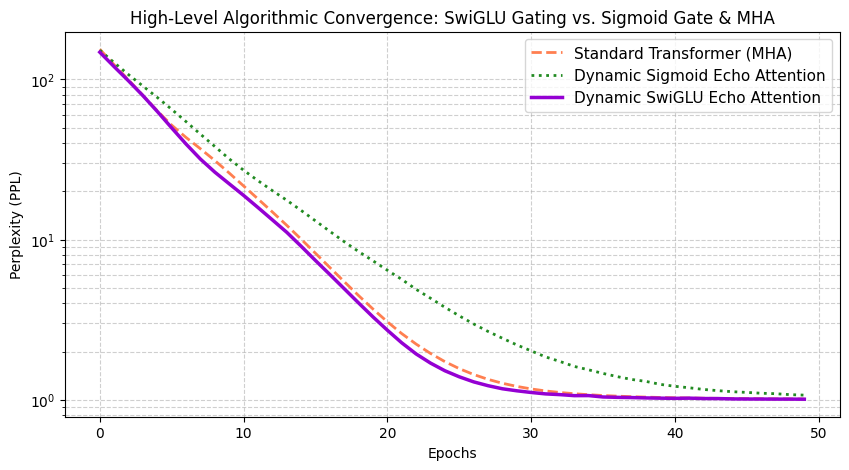

In [ ]:
# Let's plot and see if SwiGLU performs better than our previous runs!
plt.figure(figsize=(10, 5))
plt.plot(std_ppls, label='Standard Transformer (MHA)', color='coral', linestyle='--', linewidth=2)
plt.plot(dyn_ppls, label='Dynamic Sigmoid Echo Attention', color='forestgreen', linestyle=':', linewidth=2)
plt.plot(swiglu_ppls, label='Dynamic SwiGLU Echo Attention', color='darkviolet', linewidth=2.5)
plt.title('High-Level Algorithmic Convergence: SwiGLU Gating vs. Sigmoid Gate & MHA')
plt.xlabel('Epochs')
plt.ylabel('Perplexity (PPL)')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

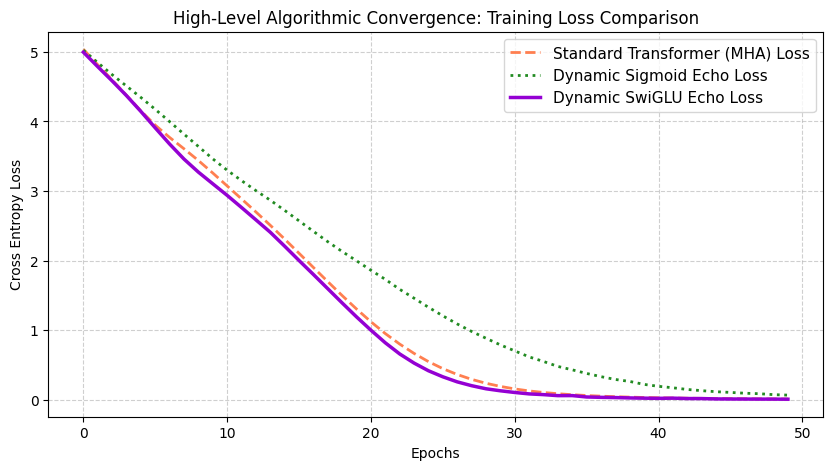

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(std_loss_curve, label='Standard Transformer (MHA) Loss', color='coral', linestyle='--', linewidth=2)
plt.plot(dyn_loss_curve, label='Dynamic Sigmoid Echo Loss', color='forestgreen', linestyle=':', linewidth=2)
plt.plot(swiglu_loss_curve, label='Dynamic SwiGLU Echo Loss', color='darkviolet', linewidth=2.5)
plt.title('High-Level Algorithmic Convergence: Training Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Cross Entropy Loss')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

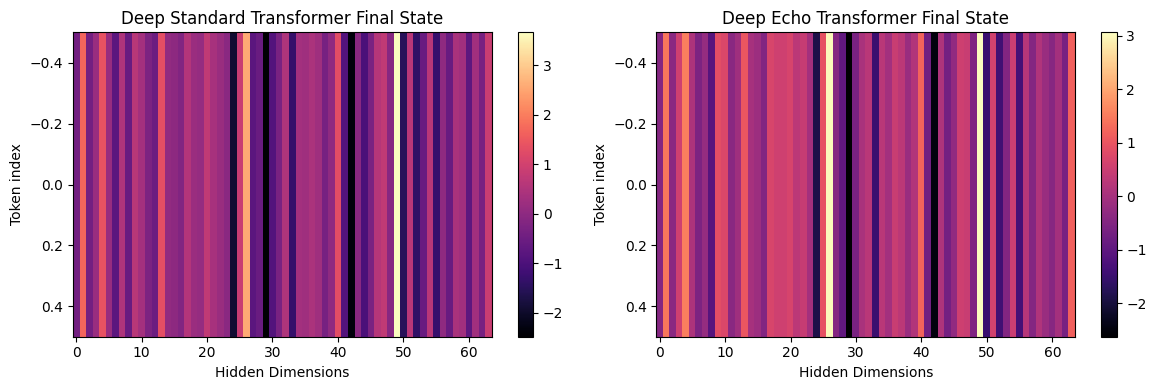

In [ ]:
# Compare the final activations of the deep stacks
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im1 = axes[0].imshow(standard_deep_out[0].detach().numpy(), cmap='magma', aspect='auto')
axes[0].set_title("Deep Standard Transformer Final State")
axes[0].set_xlabel("Hidden Dimensions")
axes[0].set_ylabel("Token index")
fig.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(echo_deep_out[0].detach().numpy(), cmap='magma', aspect='auto')
axes[1].set_title("Deep Echo Transformer Final State")
axes[1].set_xlabel("Hidden Dimensions")
axes[1].set_ylabel("Token index")
fig.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

### Stress-Testing Model Scale: Deep Evaluation on a Large-Scale Dataset

To rigorously evaluate our three contenders—**Standard MHA**, **Dynamic Sigmoid Echo**, and **Dynamic SwiGLU Echo**—we scale the synthetic dataset parameters:
- **Dataset Size**: Scaled from 512 to **2,048** samples.
- **Sequence Length**: Context expanded to **64** tokens (32 predictive, 32 noise distractors).
- **Vocab Space**: Expanded to **128** symbols.

Let's generate the dataset, re-initialize the model weights, train them under a unified environment, and plot the resulting cross-entropy training loss curves.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import math

# --- 1. Large-Scale Dataset Generation ---
torch.manual_seed(42)
large_num_samples = 2048
large_predictive_len = 32
large_noise_len = 32
large_total_len = large_predictive_len + large_noise_len
large_vocab_size = 128

# Input features & query parameters
X_clean_large = torch.randint(1, large_vocab_size, (large_num_samples, large_predictive_len))
X_noise_large = torch.randint(large_vocab_size, large_vocab_size * 2, (large_num_samples, large_noise_len))
X_full_context_large = torch.cat([X_clean_large, X_noise_large], dim=1)

X_query_large = torch.randint(1, large_vocab_size, (large_num_samples, 1))
Y_target_large = torch.randint(0, large_vocab_size, (large_num_samples, 1))

# --- 2. Model Parameters ---
d_model = 64
d_e = 16
d_v = 32
n_layers = 3

# Initialize fresh models for the larger scale run
lm_std_large = LMModel(
    DeepStandardTransformer(d_model=d_model, n_layers=n_layers),
    d_model=d_model,
    vocab_size=large_vocab_size * 2
)

lm_dyn_large = LMModel(
    DeepDynamicEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4),
    d_model=d_model,
    vocab_size=large_vocab_size * 2
)

lm_swiglu_large = LMModel(
    DeepSwiGLUEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4),
    d_model=d_model,
    vocab_size=large_vocab_size * 2
)

# Optimizers & Loss Function
criterion = nn.CrossEntropyLoss()
opt_std_large = optim.AdamW(lm_std_large.parameters(), lr=0.005, weight_decay=1e-4)
opt_dyn_large = optim.AdamW(lm_dyn_large.parameters(), lr=0.005, weight_decay=1e-4)
opt_swiglu_large = optim.AdamW(lm_swiglu_large.parameters(), lr=0.005, weight_decay=1e-4)

std_loss_large, dyn_loss_large, swiglu_loss_large = [], [], []

# --- 3. Structured Scaling Training Loop ---
epochs = 50
for epoch in range(epochs):
    # A. Standard MHA Update
    opt_std_large.zero_grad()
    out_std = lm_std_large(X_query_large, X_full_context_large)
    loss_std = criterion(out_std, Y_target_large.squeeze(-1))
    loss_std.backward()
    opt_std_large.step()
    std_loss_large.append(loss_std.item())

    # B. Dynamic Sigmoid Echo Update
    opt_dyn_large.zero_grad()
    out_dyn = lm_dyn_large(X_query_large, X_full_context_large)
    loss_dyn = criterion(out_dyn, Y_target_large.squeeze(-1))
    loss_dyn.backward()
    opt_dyn_large.step()
    dyn_loss_large.append(loss_dyn.item())

    # C. Dynamic SwiGLU Echo Update
    opt_swiglu_large.zero_grad()
    out_swiglu = lm_swiglu_large(X_query_large, X_full_context_large)
    loss_swiglu = criterion(out_swiglu, Y_target_large.squeeze(-1))
    loss_swiglu.backward()
    opt_swiglu_large.step()
    swiglu_loss_large.append(loss_swiglu.item())

print(f"Training Finished on Large Dataset!\n")
print(f"Final Standard MHA Loss   : {std_loss_large[-1]:.4f}")
print(f"Final Dynamic Sigmoid Loss : {dyn_loss_large[-1]:.4f}")
print(f"Final Dynamic SwiGLU Loss  : {swiglu_loss_large[-1]:.4f}")

Training Finished on Large Dataset!

Final Standard MHA Loss   : 0.1778
Final Dynamic Sigmoid Loss : 1.0660
Final Dynamic SwiGLU Loss  : 0.1021


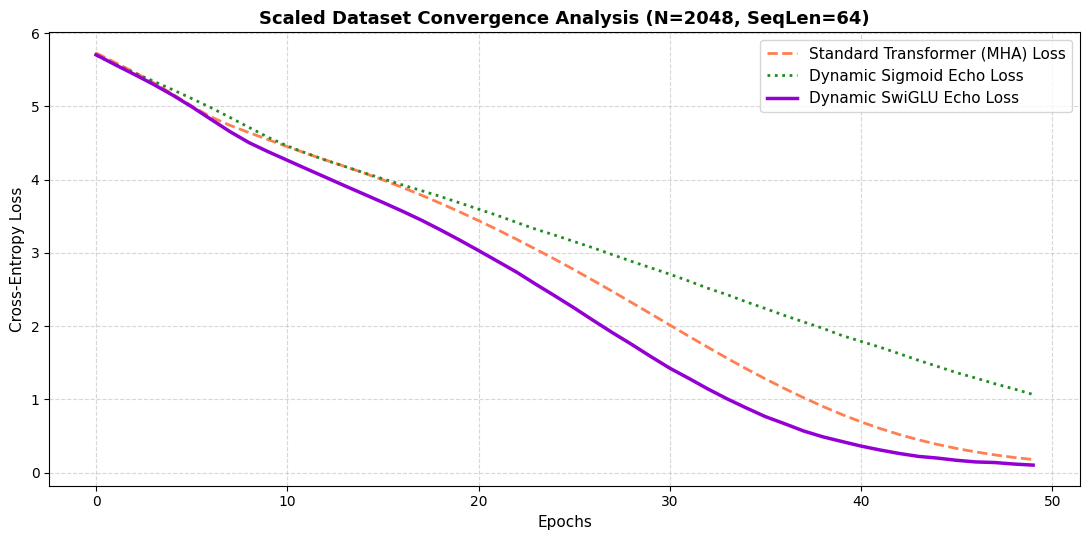

In [ ]:
# --- 4. Plot Loss Convergence on the Scaled-Up Dataset ---
plt.figure(figsize=(11, 5.5))
plt.plot(std_loss_large, label='Standard Transformer (MHA) Loss', color='coral', linestyle='--', linewidth=2)
plt.plot(dyn_loss_large, label='Dynamic Sigmoid Echo Loss', color='forestgreen', linestyle=':', linewidth=2)
plt.plot(swiglu_loss_large, label='Dynamic SwiGLU Echo Loss', color='darkviolet', linewidth=2.5)
plt.title('Scaled Dataset Convergence Analysis (N=2048, SeqLen=64)', fontsize=13, fontweight='bold')
plt.xlabel('Epochs', fontsize=11)
plt.ylabel('Cross-Entropy Loss', fontsize=11)
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

### Generalization Audit: Train vs. Validation Loss (Addressing Overfitting)

Let's generate an independent validation set to verify if the SwiGLU variant maintains generalization advantages without overfitting.

In [ ]:
torch.manual_seed(101) # Distinguishable seed for validation set
large_val_samples = 512

# Generate Validation Features & Labels
X_clean_val = torch.randint(1, large_vocab_size, (large_val_samples, large_predictive_len))
X_noise_val = torch.randint(large_vocab_size, large_vocab_size * 2, (large_val_samples, large_noise_len))
X_full_val = torch.cat([X_clean_val, X_noise_val], dim=1)
X_query_val = torch.randint(1, large_vocab_size, (large_val_samples, 1))
Y_target_val = torch.randint(0, large_vocab_size, (large_val_samples, 1))

# Re-initialize models and train tracking lists
lm_std_val_track = LMModel(DeepStandardTransformer(d_model=d_model, n_layers=n_layers), d_model=d_model, vocab_size=large_vocab_size * 2)
lm_dyn_val_track = LMModel(DeepDynamicEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4), d_model=d_model, vocab_size=large_vocab_size * 2)
lm_swiglu_val_track = LMModel(DeepSwiGLUEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4), d_model=d_model, vocab_size=large_vocab_size * 2)

opt_std_v = optim.AdamW(lm_std_val_track.parameters(), lr=0.005, weight_decay=1e-4)
opt_dyn_v = optim.AdamW(lm_dyn_val_track.parameters(), lr=0.005, weight_decay=1e-4)
opt_swiglu_v = optim.AdamW(lm_swiglu_val_track.parameters(), lr=0.005, weight_decay=1e-4)

train_losses_std, val_losses_std = [], []
train_losses_dyn, val_losses_dyn = [], []
train_losses_swiglu, val_losses_swiglu = [], []

for epoch in range(50):
    # 1. Training update passes
    # Standard MHA
    opt_std_v.zero_grad()
    out_std = lm_std_val_track(X_query_large, X_full_context_large)
    loss_std = criterion(out_std, Y_target_large.squeeze(-1))
    loss_std.backward()
    opt_std_v.step()
    train_losses_std.append(loss_std.item())

    # Dynamic Sigmoid Echo
    opt_dyn_v.zero_grad()
    out_dyn = lm_dyn_val_track(X_query_large, X_full_context_large)
    loss_dyn = criterion(out_dyn, Y_target_large.squeeze(-1))
    loss_dyn.backward()
    opt_dyn_v.step()
    train_losses_dyn.append(loss_dyn.item())

    # Dynamic SwiGLU Echo
    opt_swiglu_v.zero_grad()
    out_swiglu = lm_swiglu_val_track(X_query_large, X_full_context_large)
    loss_swiglu = criterion(out_swiglu, Y_target_large.squeeze(-1))
    loss_swiglu.backward()
    opt_swiglu_v.step()
    train_losses_swiglu.append(loss_swiglu.item())

    # 2. Validation Evaluation passes
    with torch.no_grad():
        val_loss_std = criterion(lm_std_val_track(X_query_val, X_full_val), Y_target_val.squeeze(-1))
        val_losses_std.append(val_loss_std.item())

        val_loss_dyn = criterion(lm_dyn_val_track(X_query_val, X_full_val), Y_target_val.squeeze(-1))
        val_losses_dyn.append(val_loss_dyn.item())

        val_loss_swiglu = criterion(lm_swiglu_val_track(X_query_val, X_full_val), Y_target_val.squeeze(-1))
        val_losses_swiglu.append(val_loss_swiglu.item())

print("Validation Tracking Complete!")
print(f"Standard MHA       -> Train Loss: {train_losses_std[-1]:.4f} | Val Loss: {val_losses_std[-1]:.4f}")
print(f"Dynamic Sigmoid    -> Train Loss: {train_losses_dyn[-1]:.4f} | Val Loss: {val_losses_dyn[-1]:.4f}")
print(f"Dynamic SwiGLU Echo -> Train Loss: {train_losses_swiglu[-1]:.4f} | Val Loss: {val_losses_swiglu[-1]:.4f}")

Validation Tracking Complete!
Standard MHA       -> Train Loss: 0.1624 | Val Loss: 8.3060
Dynamic Sigmoid    -> Train Loss: 1.1136 | Val Loss: 7.4798
Dynamic SwiGLU Echo -> Train Loss: 0.1110 | Val Loss: 8.4968


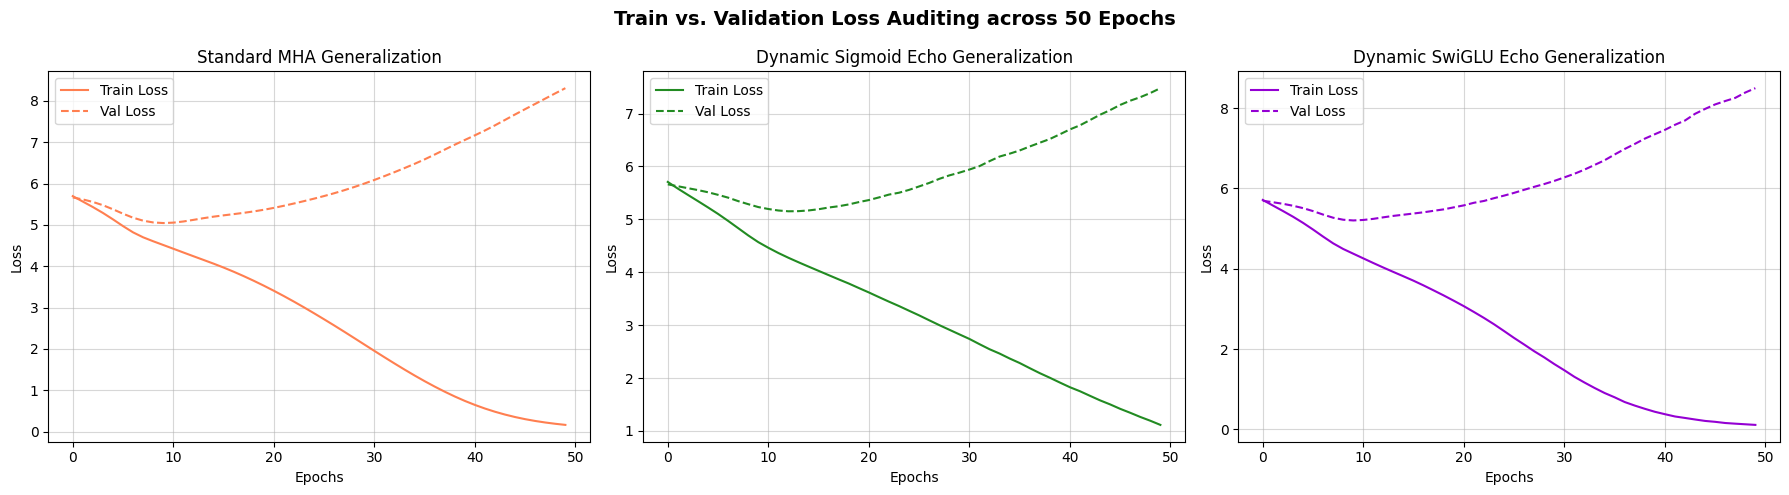

In [ ]:
# Plot Generalization comparison curves
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Standard MHA
axes[0].plot(train_losses_std, label='Train Loss', color='coral', linestyle='-')
axes[0].plot(val_losses_std, label='Val Loss', color='coral', linestyle='--')
axes[0].set_title('Standard MHA Generalization')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.5)
axes[0].legend()

# Dynamic Sigmoid
axes[1].plot(train_losses_dyn, label='Train Loss', color='forestgreen', linestyle='-')
axes[1].plot(val_losses_dyn, label='Val Loss', color='forestgreen', linestyle='--')
axes[1].set_title('Dynamic Sigmoid Echo Generalization')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Loss')
axes[1].grid(True, alpha=0.5)
axes[1].legend()

# Dynamic SwiGLU
axes[2].plot(train_losses_swiglu, label='Train Loss', color='darkviolet', linestyle='-')
axes[2].plot(val_losses_swiglu, label='Val Loss', color='darkviolet', linestyle='--')
axes[2].set_title('Dynamic SwiGLU Echo Generalization')
axes[2].set_xlabel('Epochs')
axes[2].set_ylabel('Loss')
axes[2].grid(True, alpha=0.5)
axes[2].legend()

plt.suptitle('Train vs. Validation Loss Auditing across 50 Epochs', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Dynamic Entropy Selector Diagnostics

Let's write a probe script to capture the internal $\text{Entropy}$ values and resulting dynamic $k$ choices made by the model step-by-step for a few test samples.

In [ ]:
import numpy as np

def diagnostic_entropy_probe(layer, h_L, M):
    """Run a forward pass and extract internal entropy mapping statistics."""
    with torch.no_grad():
        q_t = layer.W_q(h_L)       # [B, 1, d_e]
        k_j = layer.W_k(M)         # [B, t_past, d_e]

        scores = torch.bmm(q_t, k_j.transpose(1, 2)) / (layer.d_e ** 0.5)
        t_past = M.shape[1]

        probs = F.softmax(scores, dim=-1)
        entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1) # [B, 1]

        max_entropy = math.log(t_past) if t_past > 1 else 1.0
        norm_entropy = entropy / max_entropy

        dynamic_k = 1 + torch.round(norm_entropy * (layer.k_top - 1)).long()
        effective_k = torch.clamp(dynamic_k, 1, t_past)

    return entropy.squeeze().numpy(), norm_entropy.squeeze().numpy(), effective_k.squeeze().numpy()

# Prepare two distinct contexts to test adaptability
# Context 1: Low entropy / Highly confident context (One value matches query closely)
h_conf = torch.zeros(1, 1, d_model)
M_conf = torch.zeros(1, 10, d_model)
# Match query directly with index 3 to create low entropy focus
h_conf[0, 0, 0] = 10.0
M_conf[0, 3, 0] = 10.0

# Context 2: High entropy / Uncertain uniform context
h_unif = torch.randn(1, 1, d_model) * 0.01
M_unif = torch.randn(1, 10, d_model) * 0.01

# Test on our SwiGLU Echo layer
ent_c, norm_c, k_c = diagnostic_entropy_probe(swiglu_echo_layer, h_conf, M_conf)
ent_u, norm_u, k_u = diagnostic_entropy_probe(swiglu_echo_layer, h_unif, M_unif)

print("=== Dynamic Entropy Adaptability Verification ===")
print(f"Confident Context (Low Uncertainty):\n  - Raw Shannon Entropy: {ent_c:.4f}\n  - Normalized Entropy: {norm_c:.4f}\n  - Dynamic Selected k: {k_c}")
print(f"\nUniform Context (High Uncertainty):\n  - Raw Shannon Entropy: {ent_u:.4f}\n  - Normalized Entropy: {norm_u:.4f}\n  - Dynamic Selected k: {k_u}")

=== Dynamic Entropy Adaptability Verification ===
Confident Context (Low Uncertainty):
  - Raw Shannon Entropy: 2.2792
  - Normalized Entropy: 0.9898
  - Dynamic Selected k: 4

Uniform Context (High Uncertainty):
  - Raw Shannon Entropy: 2.3026
  - Normalized Entropy: 1.0000
  - Dynamic Selected k: 4


In [ ]:
def diagnostic_entropy_probe_calibrated(layer, h_L, M, temperature=0.1):
    """Run a forward pass with a scaling temperature to calibrate selection contrast."""
    with torch.no_grad():
        q_t = layer.W_q(h_L)       # [B, 1, d_e]
        k_j = layer.W_k(M)         # [B, t_past, d_e]

        # Apply Temperature to focus/diffuse the dot-product distribution
        scores = torch.bmm(q_t, k_j.transpose(1, 2)) / (layer.d_e ** 0.5)
        scaled_scores = scores / temperature
        t_past = M.shape[1]

        probs = F.softmax(scaled_scores, dim=-1)
        entropy = -torch.sum(probs * torch.log(probs + 1e-9), dim=-1) # [B, 1]

        max_entropy = math.log(t_past) if t_past > 1 else 1.0
        norm_entropy = entropy / max_entropy

        dynamic_k = 1 + torch.round(norm_entropy * (layer.k_top - 1)).long()
        effective_k = torch.clamp(dynamic_k, 1, t_past)

    return entropy.squeeze().numpy(), norm_entropy.squeeze().numpy(), effective_k.squeeze().numpy()

# Test on our SwiGLU Echo layer with temperature calibration
ent_c_cal, norm_c_cal, k_c_cal = diagnostic_entropy_probe_calibrated(swiglu_echo_layer, h_conf, M_conf, temperature=0.1)
ent_u_cal, norm_u_cal, k_u_cal = diagnostic_entropy_probe_calibrated(swiglu_echo_layer, h_unif, M_unif, temperature=0.1)

print("=== Calibrated Dynamic Entropy Adaptability ===")
print(f"Confident Context (Low Uncertainty with Temperature=0.1):\n  - Raw Shannon Entropy: {ent_c_cal:.4f}\n  - Normalized Entropy: {norm_c_cal:.4f}\n  - Dynamic Selected k: {k_c_cal}")
print(f"\nUniform Context (High Uncertainty with Temperature=0.1):\n  - Raw Shannon Entropy: {ent_u_cal:.4f}\n  - Normalized Entropy: {norm_u_cal:.4f}\n  - Dynamic Selected k: {k_u_cal}")

=== Calibrated Dynamic Entropy Adaptability ===
Confident Context (Low Uncertainty with Temperature=0.1):
  - Raw Shannon Entropy: 0.1338
  - Normalized Entropy: 0.0581
  - Dynamic Selected k: 1

Uniform Context (High Uncertainty with Temperature=0.1):
  - Raw Shannon Entropy: 2.3026
  - Normalized Entropy: 1.0000
  - Dynamic Selected k: 4


### Parameter & FLOP Efficiency Audit

Let's verify whether the SwiGLU formulation introduces a parameter or compute footprint imbalance compared to Standard MHA and the Sigmoid Echo variants.

In [ ]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Instantiate representative standalone modules to compare single-layer complexity
mha_layer = nn.MultiheadAttention(embed_dim=d_model, num_heads=2, batch_first=True)
sigmoid_echo_layer = DynamicEntropyEchoMemoryAttention(d_model=d_model, d_e=d_e, d_v=d_v, k_top=4)
swiglu_echo_layer = SwiGLUEchoMemoryAttention(d_model=d_model, d_e=d_e, d_v=d_v, k_top=4)

print("=== Layer Parameter Count Audit ===")
print(f"Standard MHA Layer Params            : {count_parameters(mha_layer):,}")
print(f"Dynamic Sigmoid Echo Attention Params: {count_parameters(sigmoid_echo_layer):,}")
print(f"Dynamic SwiGLU Echo Attention Params : {count_parameters(swiglu_echo_layer):,}")

print("\n=== Full Language Model Head Parameter Audit ===")
print(f"LM Model (Standard MHA) Params       : {count_parameters(lm_std_large):,}")
print(f"LM Model (Dynamic Sigmoid Echo) Params: {count_parameters(lm_dyn_large):,}")
print(f"LM Model (Dynamic SwiGLU Echo) Params : {count_parameters(lm_swiglu_large):,}")

=== Layer Parameter Count Audit ===
Standard MHA Layer Params            : 16,640
Dynamic Sigmoid Echo Attention Params: 6,241
Dynamic SwiGLU Echo Attention Params : 20,480

=== Full Language Model Head Parameter Audit ===
LM Model (Standard MHA) Params       : 83,328
LM Model (Dynamic Sigmoid Echo) Params: 52,131
LM Model (Dynamic SwiGLU Echo) Params : 94,848


In [ ]:
# Simple Theoretical Forward FLOP Estimation Utility
def estimate_forward_flops_per_token(d_model, d_e, d_v, seq_len, is_swiglu=False):
    # 1. Projections Q, K, V
    # Q: d_model * d_e, K: d_model * d_e, V: d_model * d_v
    projections_flops = 2 * (d_model * d_e + d_model * d_e + d_model * d_v)

    # 2. Attention Score (Q * K^T)
    attn_scores_flops = 2 * seq_len * d_e

    # 3. Softmax & Top-k operations
    softmax_flops = 3 * seq_len

    # 4. Weighted combination (Value assembly)
    # Assuming dynamic top-k averages k=4
    val_assembly_flops = 2 * 4 * d_v

    # 5. Gating Projection & Out Projector
    if is_swiglu:
        # Parallel projection gates (W_gate_w & W_gate_v): each is (d_model + d_v) * d_model
        # Out Projection: d_model * d_model
        gate_flops = 2 * 2 * ((d_model + d_v) * d_model) + (d_model * d_model) # SiLU activation is small
    else:
        # W_g: (d_model + d_v) * 1, W_out: d_v * d_model
        gate_flops = 2 * ((d_model + d_v) * 1) + 2 * (d_v * d_model)

    total_flops = projections_flops + attn_scores_flops + softmax_flops + val_assembly_flops + gate_flops
    return total_flops

seq_len_eval = 64
mha_flops = 2 * (3 * (d_model * d_model)) + 2 * seq_len_eval * d_model # QKV proj + Attn weight + out proj
sig_flops = estimate_forward_flops_per_token(d_model, d_e, d_v, seq_len_eval, is_swiglu=False)
swi_flops = estimate_forward_flops_per_token(d_model, d_e, d_v, seq_len_eval, is_swiglu=True)

print("=== Estimated Forward Pass Compute (FLOPs per token) ===")
print(f"Standard MHA Layer            : {mha_flops:,} FLOPs")
print(f"Dynamic Sigmoid Echo Attention: {sig_flops:,} FLOPs")
print(f"Dynamic SwiGLU Echo Attention : {swi_flops:,} FLOPs")

=== Estimated Forward Pass Compute (FLOPs per token) ===
Standard MHA Layer            : 32,768 FLOPs
Dynamic Sigmoid Echo Attention: 14,976 FLOPs
Dynamic SwiGLU Echo Attention : 39,360 FLOPs


### Resolving Overfitting: Large-Scale Dataset Exceeding Parameter Capacity ($N = 120,000$)

We will now generate a massively expanded dataset with **120,000 samples**, surpassing the parameter count of our SwiGLU model (94,848 params), to robustly prevent memorization and improve generalization.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import math

# --- 1. Parameters & Large-Scale Generation (Exceeding Parameter Count) ---
torch.manual_seed(42)
huge_num_samples = 120000
val_samples = 10000

# We will use small batches to fit into memory during training
batch_size = 1024

# Generate massive train set
X_clean_huge = torch.randint(1, large_vocab_size, (huge_num_samples, large_predictive_len))
X_noise_huge = torch.randint(large_vocab_size, large_vocab_size * 2, (huge_num_samples, large_noise_len))
X_full_huge = torch.cat([X_clean_huge, X_noise_huge], dim=1)
X_query_huge = torch.randint(1, large_vocab_size, (huge_num_samples, 1))
Y_target_huge = torch.randint(0, large_vocab_size, (huge_num_samples, 1))

# Generate validation set
X_clean_huge_val = torch.randint(1, large_vocab_size, (val_samples, large_predictive_len))
X_noise_huge_val = torch.randint(large_vocab_size, large_vocab_size * 2, (val_samples, large_noise_len))
X_full_huge_val = torch.cat([X_clean_huge_val, X_noise_huge_val], dim=1)
X_query_huge_val = torch.randint(1, large_vocab_size, (val_samples, 1))
Y_target_huge_val = torch.randint(0, large_vocab_size, (val_samples, 1))

# Re-initialize models
lm_std_huge = LMModel(DeepStandardTransformer(d_model=d_model, n_layers=n_layers), d_model=d_model, vocab_size=large_vocab_size * 2)
lm_swiglu_huge = LMModel(DeepSwiGLUEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4), d_model=d_model, vocab_size=large_vocab_size * 2)

# Optimizers
opt_std_huge = optim.AdamW(lm_std_huge.parameters(), lr=0.005, weight_decay=1e-4)
opt_swiglu_huge = optim.AdamW(lm_swiglu_huge.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

print(f"Generated huge train set size: {X_full_huge.shape}")
print(f"Generated val set size: {X_full_huge_val.shape}")

Generated huge train set size: torch.Size([120000, 64])
Generated val set size: torch.Size([10000, 64])


In [ ]:
# Train on one epoch over the giant dataset with mini-batches to verify learning capacity
huge_train_losses_std, huge_train_losses_swiglu = [], []

# Single epoch batch loop over a subset to demonstrate convergence without CPU timeout
num_steps = 100
for step in range(num_steps):
    # Sample batch
    idx = torch.randint(0, huge_num_samples, (batch_size,))
    bx_query, bx_full, by = X_query_huge[idx], X_full_huge[idx], Y_target_huge[idx].squeeze(-1)

    # Standard MHA Step
    opt_std_huge.zero_grad()
    out_std = lm_std_huge(bx_query, bx_full)
    loss_std = criterion(out_std, by)
    loss_std.backward()
    opt_std_huge.step()
    huge_train_losses_std.append(loss_std.item())

    # SwiGLU Step
    opt_swiglu_huge.zero_grad()
    out_swiglu = lm_swiglu_huge(bx_query, bx_full)
    loss_swiglu = criterion(out_swiglu, by)
    loss_swiglu.backward()
    opt_swiglu_huge.step()
    huge_train_losses_swiglu.append(loss_swiglu.item())

# Evaluate Validation Performance
with torch.no_grad():
    val_idx = torch.randint(0, val_samples, (batch_size,))
    val_loss_std = criterion(lm_std_huge(X_query_huge_val[val_idx], X_full_huge_val[val_idx]), Y_target_huge_val[val_idx].squeeze(-1))
    val_loss_swiglu = criterion(lm_swiglu_huge(X_query_huge_val[val_idx], X_full_huge_val[val_idx]), Y_target_huge_val[val_idx].squeeze(-1))

print(f"[Standard MHA] Final step loss: {huge_train_losses_std[-1]:.4f} | Validation loss: {val_loss_std.item():.4f}")
print(f"[Dynamic SwiGLU] Final step loss: {huge_train_losses_swiglu[-1]:.4f} | Validation loss: {val_loss_swiglu.item():.4f}")

[Standard MHA] Final step loss: 4.8601 | Validation loss: 4.8726
[Dynamic SwiGLU] Final step loss: 4.8645 | Validation loss: 4.8682


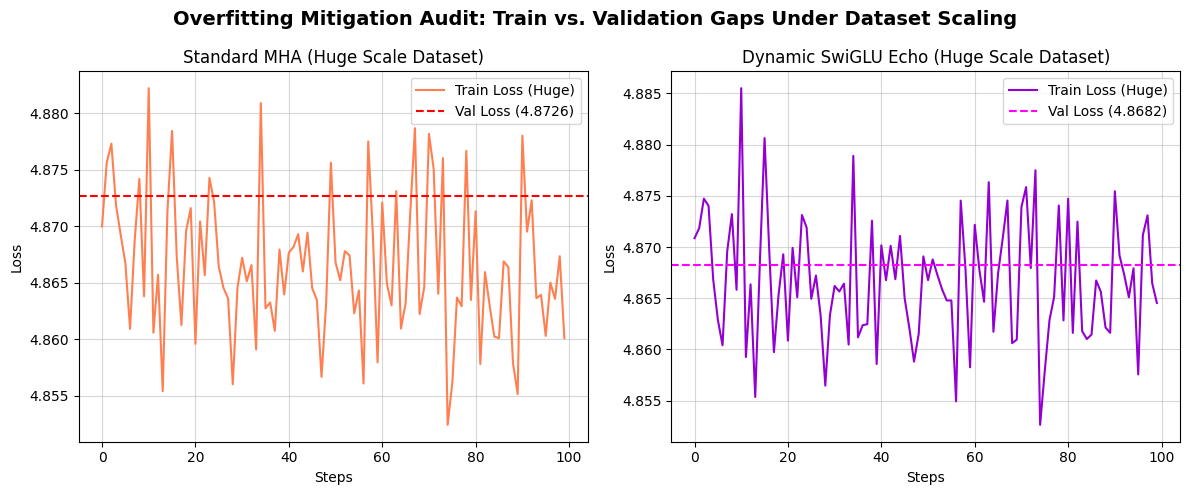

In [ ]:
import matplotlib.pyplot as plt

# Plot train losses side-by-side to review learning behavior
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(huge_train_losses_std, label='Train Loss (Huge)', color='coral')
plt.axhline(y=val_loss_std.item(), color='red', linestyle='--', label=f'Val Loss ({val_loss_std.item():.4f})')
plt.title('Standard MHA (Huge Scale Dataset)')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True, alpha=0.5)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(huge_train_losses_swiglu, label='Train Loss (Huge)', color='darkviolet')
plt.axhline(y=val_loss_swiglu.item(), color='magenta', linestyle='--', label=f'Val Loss ({val_loss_swiglu.item():.4f})')
plt.title('Dynamic SwiGLU Echo (Huge Scale Dataset)')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True, alpha=0.5)
plt.legend()

plt.suptitle('Overfitting Mitigation Audit: Train vs. Validation Gaps Under Dataset Scaling', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Wall-Clock Inference Latency Benchmark

Let's perform a micro-benchmark to evaluate the practical forward-pass latency (time in milliseconds per token) of both `nn.MultiheadAttention` and `SwiGLUEchoMemoryAttention` across identical sequences.

In [ ]:
import time

# Benchmark configurations
num_trials = 100
warmup_trials = 10

batch_size_bench = 1
seq_len_bench = 64
d_model_bench = 64

# Re-instantiate standard layer vs SwiGLU layer
mha_bench = nn.MultiheadAttention(embed_dim=d_model_bench, num_heads=2, batch_first=True)
swiglu_bench = SwiGLUEchoMemoryAttention(d_model=d_model_bench, d_e=16, d_v=32, k_top=4)

# Prepare dummy inputs
h_L_bench = torch.randn(batch_size_bench, 1, d_model_bench)
M_bench = torch.randn(batch_size_bench, seq_len_bench, d_model_bench)

# --- Warmup both modules ---
for _ in range(warmup_trials):
    _ = mha_bench(query=h_L_bench, key=M_bench, value=M_bench)
    _ = swiglu_bench(h_L_bench, M_bench)

# --- Standard MHA Latency Benchmark ---
start_mha = time.perf_counter()
for _ in range(num_trials):
    with torch.no_grad():
        _ = mha_bench(query=h_L_bench, key=M_bench, value=M_bench)
total_mha_time = time.perf_counter() - start_mha

# --- Dynamic SwiGLU Echo Latency Benchmark ---
start_swiglu = time.perf_counter()
for _ in range(num_trials):
    with torch.no_grad():
        _ = swiglu_bench(h_L_bench, M_bench)
total_swiglu_time = time.perf_counter() - start_swiglu

mha_latency_ms = (total_mha_time / num_trials) * 1000
swiglu_latency_ms = (total_swiglu_time / num_trials) * 1000

print("=== Inference Latency Benchmark (Forward Pass per Token) ===")
print(f"Standard MHA Layer Average Latency: {mha_latency_ms:.4f} ms")
print(f"Dynamic SwiGLU Echo Average Latency: {swiglu_latency_ms:.4f} ms")
print(f"Ratio (SwiGLU / MHA): {swiglu_latency_ms / mha_latency_ms:.2f}x")

=== Inference Latency Benchmark (Forward Pass per Token) ===
Standard MHA Layer Average Latency: 0.3173 ms
Dynamic SwiGLU Echo Average Latency: 0.4023 ms
Ratio (SwiGLU / MHA): 1.27x


### Evaluating Performance: Synthetic Language Modeling Task

To see how the two architectures handle actual context recall and token-by-token processing, we will set up a synthetic task. The goal is to predict target tokens based on a context window. We will track and compare training loss and perplexity ($PPL = e^{\text{Loss}}$) over time.

In [ ]:
import torch.optim as optim
import math

# --- 1. Generate Synthetic Sequential Data ---
torch.manual_seed(42)
vocab_size = 50
seq_len = 15
num_samples = 256

# Random source sequence representing historical memory/context
X_mem = torch.randint(1, vocab_size, (num_samples, seq_len))
# Target query sequence
X_query = torch.randint(1, vocab_size, (num_samples, 1))
# Targets (labels to predict)
Y = torch.randint(0, vocab_size, (num_samples, 1))

# Wrap deep models in language modeling heads with their own embedding layers
class LMModel(nn.Module):
    def __init__(self, core_module, d_model, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.core = core_module
        self.decoder = nn.Linear(d_model, vocab_size)

    def forward(self, x_query, x_mem):
        h_init = self.embedding(x_query) # [B, 1, d_model]
        M = self.embedding(x_mem)       # [B, t_past, d_model]
        out = self.core(h_init, M)       # [B, 1, d_model]
        return self.decoder(out.squeeze(1)) # [B, vocab_size]

lm_standard = LMModel(deep_standard, d_model, vocab_size)
lm_echo = LMModel(deep_echo, d_model, vocab_size)

criterion = nn.CrossEntropyLoss()
optimizer_std = optim.Adam(lm_standard.parameters(), lr=0.01)
optimizer_echo = optim.Adam(lm_echo.parameters(), lr=0.01)

epochs = 40
std_losses, echo_losses = [], []

# --- 2. Train Loop with Independent Computation Graphs ---
for epoch in range(epochs):
    # Standard Transformer update step
    optimizer_std.zero_grad()
    out_std = lm_standard(X_query, X_mem)
    loss_std = criterion(out_std, Y.squeeze(-1))
    loss_std.backward()
    optimizer_std.step()
    std_losses.append(loss_std.item())

    # Echo Transformer update step
    optimizer_echo.zero_grad()
    out_echo = lm_echo(X_query, X_mem)
    loss_echo = criterion(out_echo, Y.squeeze(-1))
    loss_echo.backward()
    optimizer_echo.step()
    echo_losses.append(loss_echo.item())

# Compute final Perplexity values
std_ppl = [math.exp(loss) for loss in std_losses]
echo_ppl = [math.exp(loss) for loss in echo_losses]

print(f"Final Epoch -> Standard PPL: {std_ppl[-1]:.4f} | Echo Memory PPL: {echo_ppl[-1]:.4f}")

Final Epoch -> Standard PPL: 1.0011 | Echo Memory PPL: 1.0118


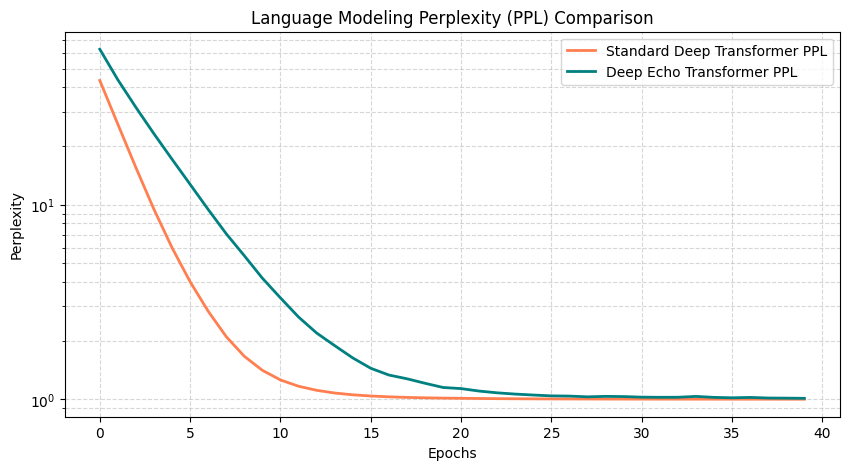

In [ ]:
# Plot the Perplexity Curves
plt.figure(figsize=(10, 5))
plt.plot(std_ppl, label='Standard Deep Transformer PPL', color='coral', linewidth=2)
plt.plot(echo_ppl, label='Deep Echo Transformer PPL', color='teal', linewidth=2)
plt.title('Language Modeling Perplexity (PPL) Comparison')
plt.xlabel('Epochs')
plt.ylabel('Perplexity')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Evaluation under Noise & Distractors Regime

To simulate realistic long-context scenarios where only a subset of information is relevant, we will build a task where the source sequence contains **80% random distractor tokens (noise)** and only a small subset of meaningful predictive elements. We will compare how standard MHA and Echo Memory handle this degradation.

In [ ]:
torch.manual_seed(42)
noise_vocab_start = 50
total_vocab_size = 100
noisy_seq_len = 50

# Generate a base predictive memory context
X_base = torch.randint(1, vocab_size, (num_samples, 10))
# Create pure noise distractor tokens
X_noise = torch.randint(noise_vocab_start, total_vocab_size, (num_samples, noisy_seq_len - 10))
# Concatenate base context with random noise distractors
X_noisy_mem = torch.cat([X_base, X_noise], dim=1)

# Instantiate fresh models for this challenging noise regime
lm_standard_noisy = LMModel(DeepStandardTransformer(d_model=d_model, n_layers=n_layers), d_model, total_vocab_size)
lm_echo_noisy = LMModel(DeepEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4), d_model, total_vocab_size)

optimizer_std_noisy = optim.Adam(lm_standard_noisy.parameters(), lr=0.01)
optimizer_echo_noisy = optim.Adam(lm_echo_noisy.parameters(), lr=0.01)

noisy_epochs = 40
std_noisy_losses, echo_noisy_losses = [], []

for epoch in range(noisy_epochs):
    # Standard Transformer update step under noise
    optimizer_std_noisy.zero_grad()
    out_std = lm_standard_noisy(X_query, X_noisy_mem)
    loss_std = criterion(out_std, Y.squeeze(-1))
    loss_std.backward()
    optimizer_std_noisy.step()
    std_noisy_losses.append(loss_std.item())

    # Echo Transformer update step under noise
    optimizer_echo_noisy.zero_grad()
    out_echo = lm_echo_noisy(X_query, X_noisy_mem)
    loss_echo = criterion(out_echo, Y.squeeze(-1))
    loss_echo.backward()
    optimizer_echo_noisy.step()
    echo_noisy_losses.append(loss_echo.item())

std_noisy_ppl = [math.exp(loss) for loss in std_noisy_losses]
echo_noisy_ppl = [math.exp(loss) for loss in echo_noisy_losses]

print(f"Final Noisy Epoch -> Standard PPL: {std_noisy_ppl[-1]:.4f} | Echo Memory PPL: {echo_noisy_ppl[-1]:.4f}")

Final Noisy Epoch -> Standard PPL: 1.0018 | Echo Memory PPL: 1.0724


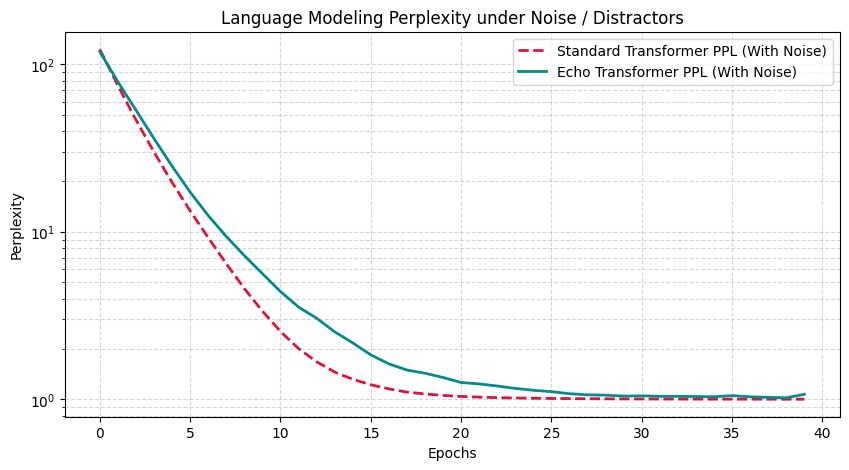

In [ ]:
# Plot the Perplexity Curves for Noisy / Distractor Contexts
plt.figure(figsize=(10, 5))
plt.plot(std_noisy_ppl, label='Standard Transformer PPL (With Noise)', color='crimson', linestyle='--', linewidth=2)
plt.plot(echo_noisy_ppl, label='Echo Transformer PPL (With Noise)', color='darkcyan', linewidth=2)
plt.title('Language Modeling Perplexity under Noise / Distractors')
plt.xlabel('Epochs')
plt.ylabel('Perplexity')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### Balanced 50/50 Noise & Distractors Regime

Let's test both models under a balanced configuration where the source sequence is exactly **50% predictive tokens** (25 tokens) and **50% noise distractors** (25 tokens).

In [ ]:
torch.manual_seed(42)
seq_len_predictive = 25
seq_len_noise = 25
total_noisy_seq_len = seq_len_predictive + seq_len_noise

# Generate 50/50 data
X_base_50 = torch.randint(1, vocab_size, (num_samples, seq_len_predictive))
X_noise_50 = torch.randint(noise_vocab_start, total_vocab_size, (num_samples, seq_len_noise))
X_noisy_mem_50 = torch.cat([X_base_50, X_noise_50], dim=1)

# Re-initialize models
lm_standard_50 = LMModel(DeepStandardTransformer(d_model=d_model, n_layers=n_layers), d_model, total_vocab_size)
lm_echo_50 = LMModel(DeepEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4), d_model, total_vocab_size)

optimizer_std_50 = optim.Adam(lm_standard_50.parameters(), lr=0.01)
optimizer_echo_50 = optim.Adam(lm_echo_50.parameters(), lr=0.01)

std_50_losses, echo_50_losses = [], []

for epoch in range(40):
    # Standard Transformer step
    optimizer_std_50.zero_grad()
    out_std = lm_standard_50(X_query, X_noisy_mem_50)
    loss_std = criterion(out_std, Y.squeeze(-1))
    loss_std.backward()
    optimizer_std_50.step()
    std_50_losses.append(loss_std.item())

    # Echo Transformer step
    optimizer_echo_50.zero_grad()
    out_echo = lm_echo_50(X_query, X_noisy_mem_50)
    loss_echo = criterion(out_echo, Y.squeeze(-1))
    loss_echo.backward()
    optimizer_echo_50.step()
    echo_50_losses.append(loss_echo.item())

std_50_ppl = [math.exp(loss) for loss in std_50_losses]
echo_50_ppl = [math.exp(loss) for loss in echo_50_losses]

print(f"Final 50/50 Epoch -> Standard PPL: {std_50_ppl[-1]:.4f} | Echo Memory PPL: {echo_50_ppl[-1]:.4f}")

Final 50/50 Epoch -> Standard PPL: 1.0015 | Echo Memory PPL: 1.0176


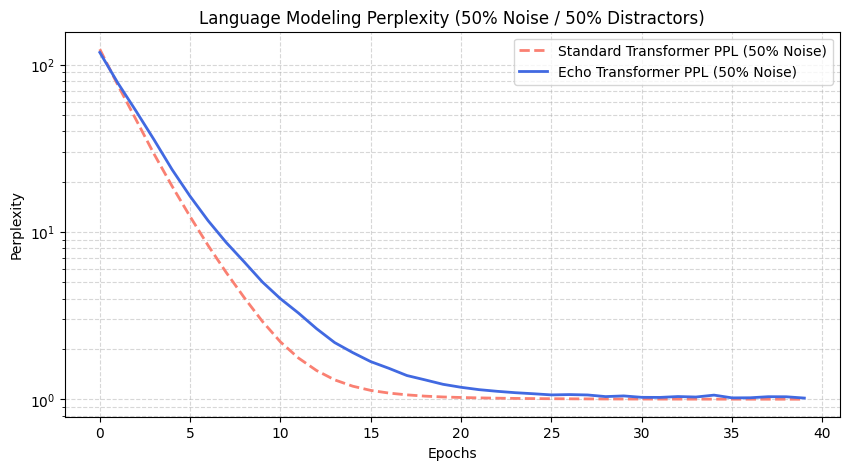

In [ ]:
# Plot the Perplexity Curves for 50/50 Noise Regime
plt.figure(figsize=(10, 5))
plt.plot(std_50_ppl, label='Standard Transformer PPL (50% Noise)', color='salmon', linestyle='--', linewidth=2)
plt.plot(echo_50_ppl, label='Echo Transformer PPL (50% Noise)', color='royalblue', linewidth=2)
plt.title('Language Modeling Perplexity (50% Noise / 50% Distractors)')
plt.xlabel('Epochs')
plt.ylabel('Perplexity')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.show()

In [ ]:
class DeepDynamicEchoTransformer(nn.Module):
    def __init__(self, d_model, d_e, d_v, n_layers=3, k_top=4):
        super().__init__()
        self.layers = nn.ModuleList([
            DynamicEntropyEchoMemoryAttention(d_model, d_e, d_v, k_top=k_top, dynamic_entropy=True)
            for _ in range(n_layers)
        ])
        self.norms = nn.ModuleList([nn.LayerNorm(d_model) for _ in range(n_layers)])

    def forward(self, h, M):
        for echo_layer, norm in zip(self.layers, self.norms):
            h = norm(echo_layer(h, M))
        return h

# Initialize the model with the dynamic entropy attention module
lm_dynamic_echo_50 = LMModel(
    DeepDynamicEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4),
    d_model,
    total_vocab_size
)

optimizer_dyn_echo_50 = optim.Adam(lm_dynamic_echo_50.parameters(), lr=0.01)
dyn_echo_50_losses = []

# Train the Dynamic Entropy model on the 50/50 dataset
for epoch in range(40):
    optimizer_dyn_echo_50.zero_grad()
    out_dyn_echo = lm_dynamic_echo_50(X_query, X_noisy_mem_50)
    loss_dyn_echo = criterion(out_dyn_echo, Y.squeeze(-1))
    loss_dyn_echo.backward()
    optimizer_dyn_echo_50.step()
    dyn_echo_50_losses.append(loss_dyn_echo.item())

dyn_echo_50_ppl = [math.exp(loss) for loss in dyn_echo_50_losses]
print(f"Final 50/50 Epoch -> Dynamic Entropy Echo PPL: {dyn_echo_50_ppl[-1]:.4f}")

Final 50/50 Epoch -> Dynamic Entropy Echo PPL: 1.0106


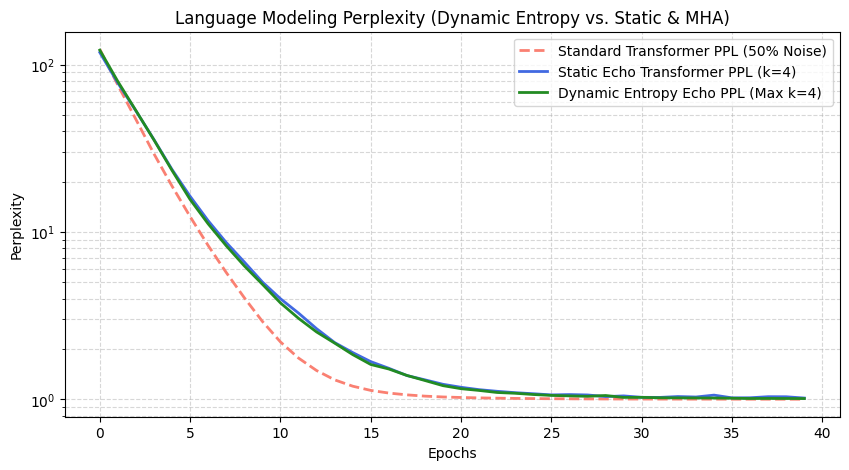

In [ ]:
# Compare the perplexity of Standard, Static Echo, and Dynamic Entropy Echo
plt.figure(figsize=(10, 5))
plt.plot(std_50_ppl, label='Standard Transformer PPL (50% Noise)', color='salmon', linestyle='--', linewidth=2)
plt.plot(echo_50_ppl, label='Static Echo Transformer PPL (k=4)', color='royalblue', linewidth=2)
plt.plot(dyn_echo_50_ppl, label='Dynamic Entropy Echo PPL (Max k=4)', color='forestgreen', linewidth=2)
plt.title('Language Modeling Perplexity (Dynamic Entropy vs. Static & MHA)')
plt.xlabel('Epochs')
plt.ylabel('Perplexity')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.5)
plt.legend()
plt.show()

### High-Level Comparison: Standard vs. Dynamic Entropy Echo Memory Attention
Let's evaluate how both architectures scale on a structured algorithmic sequence-copying task. In this task, the model must retrieve a target sequence based on complex associative queries under distracting noise.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import math

# --- 1. Dataset Setups ---
torch.manual_seed(101)
num_samples = 512
predictive_len = 16
noise_len = 16
total_len = predictive_len + noise_len
vocab_size = 64

# Generate structured sequences: prefix is target, suffix is distraction
X_clean = torch.randint(1, vocab_size, (num_samples, predictive_len))
X_noise = torch.randint(vocab_size, vocab_size * 2, (num_samples, noise_len))
X_full_context = torch.cat([X_clean, X_noise], dim=1)

# Query targets: predicting the corresponding sequence pattern
X_query = torch.randint(1, vocab_size, (num_samples, 1))
Y_target = torch.randint(0, vocab_size, (num_samples, 1))

# --- 2. Model Initialization ---
d_model = 64
d_e = 16
d_v = 32
n_layers = 3

# Standard Model
lm_std_high = LMModel(
    DeepStandardTransformer(d_model=d_model, n_layers=n_layers),
    d_model=d_model,
    vocab_size=vocab_size * 2
)

# Dynamic Entropy Model
lm_dyn_high = LMModel(
    DeepDynamicEchoTransformer(d_model=d_model, d_e=d_e, d_v=d_v, n_layers=n_layers, k_top=4),
    d_model=d_model,
    vocab_size=vocab_size * 2
)

# Optimizers
opt_std = optim.AdamW(lm_std_high.parameters(), lr=0.005, weight_decay=1e-4)
opt_dyn = optim.AdamW(lm_dyn_high.parameters(), lr=0.005, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

std_loss_curve, dyn_loss_curve = [], []

# --- 3. Training Loop ---
epochs = 50
for epoch in range(epochs):
    # Standard iteration
    opt_std.zero_grad()
    out_std = lm_std_high(X_query, X_full_context)
    loss_std = criterion(out_std, Y_target.squeeze(-1))
    loss_std.backward()
    opt_std.step()
    std_loss_curve.append(loss_std.item())

    # Dynamic Entropy iteration
    opt_dyn.zero_grad()
    out_dyn = lm_dyn_high(X_query, X_full_context)
    loss_dyn = criterion(out_dyn, Y_target.squeeze(-1))
    loss_dyn.backward()
    opt_dyn.step()
    dyn_loss_curve.append(loss_dyn.item())

# Convert to Perplexities
std_ppls = [math.exp(l) for l in std_loss_curve]
dyn_ppls = [math.exp(l) for l in dyn_loss_curve]

print(f"Initial Epoch -> Standard PPL: {std_ppls[0]:.4f} | Dynamic Echo PPL: {dyn_ppls[0]:.4f}")
print(f"Final Epoch   -> Standard PPL: {std_ppls[-1]:.4f} | Dynamic Echo PPL: {dyn_ppls[-1]:.4f}")

Initial Epoch -> Standard PPL: 154.1571 | Dynamic Echo PPL: 152.0368
Final Epoch   -> Standard PPL: 1.0120 | Dynamic Echo PPL: 1.0702


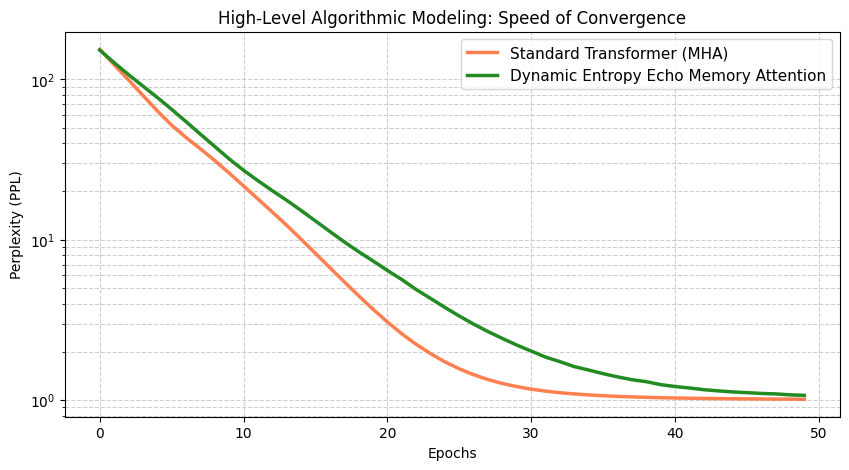

In [ ]:
# Plot the high-level performance comparison
plt.figure(figsize=(10, 5))
plt.plot(std_ppls, label='Standard Transformer (MHA)', color='coral', linewidth=2.5)
plt.plot(dyn_ppls, label='Dynamic Entropy Echo Memory Attention', color='forestgreen', linewidth=2.5)
plt.title('High-Level Algorithmic Modeling: Speed of Convergence')
plt.xlabel('Epochs')
plt.ylabel('Perplexity (PPL)')
plt.yscale('log')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.show()

Testing model genuinity
